# Hot tube beside a vertical plate (issue #1)

A 3/4" diameter tube, 140 mm long, is held at **650 °C** with its axis along x. A solid
plate, 140 × 1 × 220 mm (x × y × z, z up), stands parallel to it with a **10 mm air gap**
between the tube surface and the plate.

1. What temperature does the plate reach?
2. How many heat shields of emissivity 0.2 are needed to keep the plate below **150 °C**?
3. With no plate at all, how many shields are needed to keep the outermost shield below
   **150 °C**? ([issue #3](https://github.com/andrewgsavage/radiation/issues/3))

The model lives in [`radiation.py`](radiation.py) and is tested in [`tests/`](tests/).

## Assumptions

| Item | Value | Notes |
|---|---|---|
| Tube position | centred on the plate's height (z = 110 mm) | |
| Tube emissivity | 0.8 | oxidised steel; varied below |
| Plate emissivity | 0.8, both faces | varied below |
| Plate material | carbon steel, k = 45 W/m·K | sets how far heat spreads up the plate; varied below |
| Surroundings | 25 °C, still air, black | everything the plate doesn't see of the tube |
| Shields | 0.5 mm stainless (k = 16), ε = 0.2 both faces, same size as the plate, evenly spaced in the 10 mm gap | |
| Air between sheets | still, conducts heat (Nu = 1) | |
| Room-air convection | Churchill–Chu vertical plate, on faces open to the room | |
| Hot air rising from the tube | **ignored** | as requested |

Surfaces are gray and diffuse. Each sheet is split into 60 horizontal strips (finer near the
tube's height), so the plate's temperature can vary with height. Temperature is uniform
along x and through each sheet's thickness. With one strip per sheet the model becomes the
usual single-temperature (lumped) estimate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

from dataclasses import replace

import radiation as rad

C = 273.15
s = rad.Setup()
r_mm, gap_mm, L_mm, H_mm = s.tube_od / 2e-3, s.gap * 1e3, s.length * 1e3, s.plate_height * 1e3
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Geometry

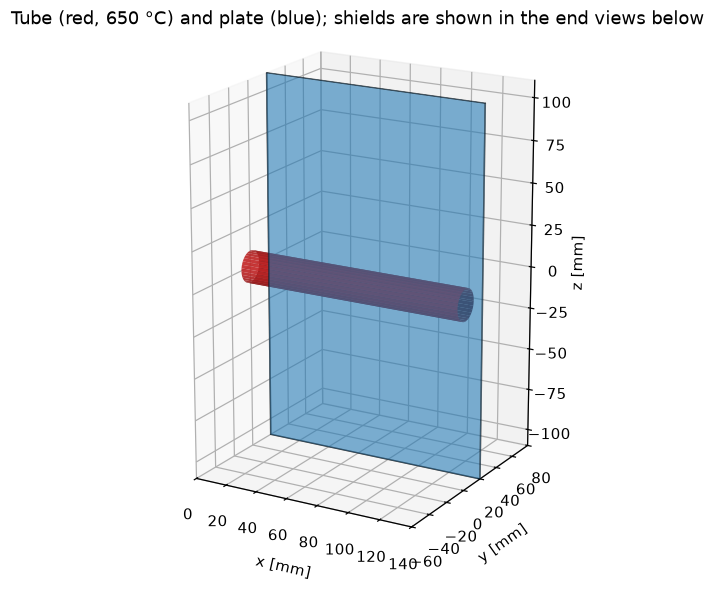

In [2]:
def box(x0, x1, y0, y1, z0, z1):
    v = np.array([[x0, y0, z0], [x1, y0, z0], [x1, y1, z0], [x0, y1, z0],
                  [x0, y0, z1], [x1, y0, z1], [x1, y1, z1], [x0, y1, z1]])
    faces = [[0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4], [2, 3, 7, 6], [1, 2, 6, 5], [0, 3, 7, 4]]
    return [v[f] for f in faces]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
phi, x = np.meshgrid(np.linspace(0, 2 * np.pi, 60), np.linspace(0, L_mm, 2))
ax.plot_surface(x, r_mm * np.cos(phi), r_mm * np.sin(phi), color="tab:red", alpha=0.9, linewidth=0)
y_plate = r_mm + gap_mm
ax.add_collection3d(Poly3DCollection(box(0, L_mm, y_plate, y_plate + 1, -H_mm / 2, H_mm / 2),
                                     facecolor="tab:blue", alpha=0.35, edgecolor="k", linewidth=0.5))
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_zlabel("z [mm]")
ax.set_xlim(0, L_mm); ax.set_ylim(-60, 80); ax.set_zlim(-H_mm / 2, H_mm / 2)
ax.set_box_aspect((L_mm, 140, H_mm))
ax.view_init(elev=18, azim=-60)
ax.set_title("Tube (red, 650 °C) and plate (blue); shields are shown in the end views below")
plt.show()

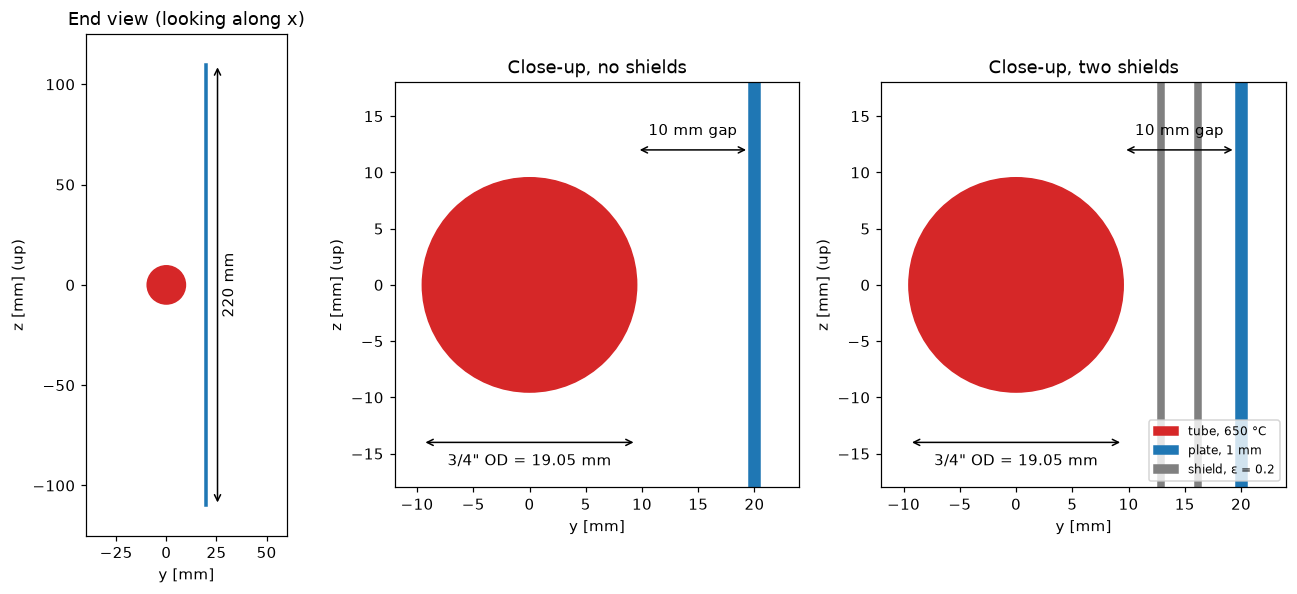

In [3]:
def section(ax, n_shields, zoom, plate=True):
    ax.add_patch(Circle((0, 0), r_mm, color="tab:red", label="tube, 650 °C"))
    if plate:
        ax.add_patch(Rectangle((r_mm + gap_mm, -H_mm / 2), 1, H_mm, color="tab:blue", label="plate, 1 mm"))
    sp = gap_mm / (n_shields + 1 if plate else n_shields)
    for k in range(n_shields):
        ax.add_patch(Rectangle((r_mm + (k + 1) * sp - 0.25, -H_mm / 2), 0.5, H_mm, color="grey",
                               label="shield, ε = 0.2" if k == 0 else None))
    ax.set_aspect("equal")
    ax.set_xlabel("y [mm]"); ax.set_ylabel("z [mm] (up)")
    if zoom:
        ax.set_xlim(-12, 24); ax.set_ylim(-18, 18)
        ax.annotate("", (r_mm, 12), (r_mm + gap_mm, 12), arrowprops=dict(arrowstyle="<->"))
        ax.text(r_mm + gap_mm / 2, 13, "10 mm gap", ha="center", va="bottom")
        ax.annotate("", (-r_mm, -14), (r_mm, -14), arrowprops=dict(arrowstyle="<->"))
        ax.text(0, -15, '3/4" OD = 19.05 mm', ha="center", va="top")
    else:
        ax.set_xlim(-40, 60); ax.set_ylim(-125, 125)
        ax.annotate("", (r_mm + gap_mm + 6, -H_mm / 2), (r_mm + gap_mm + 6, H_mm / 2),
                    arrowprops=dict(arrowstyle="<->"))
        ax.text(r_mm + gap_mm + 8, 0, "220 mm", rotation=90, va="center")
    ax.grid(False)

fig, axes = plt.subplots(1, 3, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
section(axes[0], 0, zoom=False); axes[0].set_title("End view (looking along x)")
section(axes[1], 0, zoom=True); axes[1].set_title("Close-up, no shields")
section(axes[2], 2, zoom=True); axes[2].set_title("Close-up, two shields")
axes[2].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### How much of the tube's radiation reaches the plate?

The view factor from the tube to the whole plate, compared with the textbook value for an
infinitely long tube and plate, $F = \tfrac{1}{\pi}\arctan(110/19.5)$:

In [4]:
r, c = s.tube_od / 2, s.tube_od / 2 + s.gap
F_finite = rad.tube_to_rectangle(r, s.length, c, -s.plate_height / 2, s.plate_height / 2)
F_2d = np.arctan(s.plate_height / 2 / c) / np.pi
print(f"finite 140 mm tube and plate: F = {F_finite:.3f}")
print(f"infinitely long (2-D):        F = {F_2d:.3f}")

finite 140 mm tube and plate: F = 0.394
infinitely long (2-D):        F = 0.444


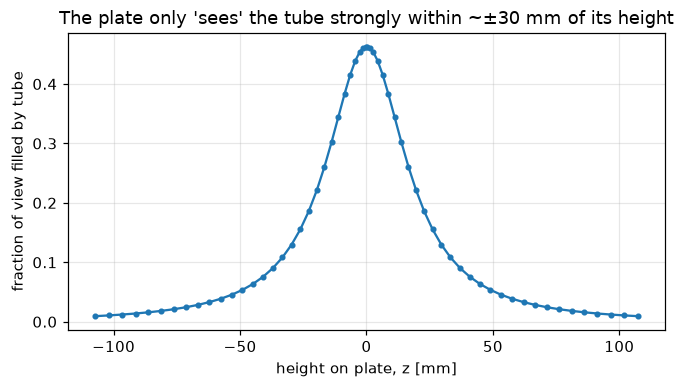

In [5]:
edges = rad.strip_edges(s.plate_height, 60)
z = 0.5 * (edges[1:] + edges[:-1])
F_strip = np.array([rad.tube_to_rectangle(r, s.length, c, lo, hi) for lo, hi in zip(edges[:-1], edges[1:])])
A_tube = np.pi * s.tube_od * s.length
F_plate_to_tube = A_tube * F_strip / (s.length * np.diff(edges))   # reciprocity, per unit plate area

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(z * 1e3, F_plate_to_tube, "o-", ms=3)
ax.set_xlabel("height on plate, z [mm]"); ax.set_ylabel("fraction of view filled by tube")
ax.set_title("The plate only 'sees' the tube strongly within ~±30 mm of its height")
plt.show()

## Part 1 — plate temperature, no shields

In [6]:
lumped = rad.solve(s, 0, n_strips=1)
dist = rad.solve(s, 0)
print(f"single-temperature (lumped) plate:       {lumped.T_plate_max - C:6.1f} °C")
print(f"temperature varying with height:  peak   {dist.T_plate_max - C:6.1f} °C  (opposite the tube)")
print(f"                                  mean   {dist.T_plate_mean - C:6.1f} °C")
print(f"                                  edges  {dist.T_sheets[-1][[0, -1]].mean() - C:6.1f} °C  (top and bottom)")
print(f"tube's net radiation: {dist.Q_radiation:.0f} W")

single-temperature (lumped) plate:        122.5 °C
temperature varying with height:  peak    187.7 °C  (opposite the tube)
                                  mean    119.0 °C
                                  edges    75.9 °C  (top and bottom)
tube's net radiation: 265 W


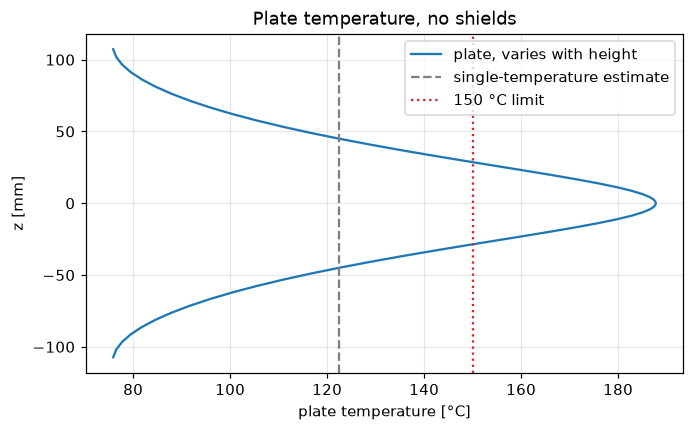

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dist.T_sheets[-1] - C, dist.z * 1e3, label="plate, varies with height")
ax.axvline(lumped.T_plate_max - C, color="grey", ls="--", label="single-temperature estimate")
ax.axvline(150, color="tab:red", ls=":", label="150 °C limit")
ax.set_xlabel("plate temperature [°C]"); ax.set_ylabel("z [mm]")
ax.set_title("Plate temperature, no shields"); ax.legend()
plt.show()

The single-temperature estimate (about 120 °C) looks safely under the limit. But the band of
plate directly opposite the tube receives about four times the plate's average radiation.
A 1 mm steel plate can't spread that heat far, so the plate peaks well above 150 °C.
**The peak, not the average, decides part 2.**

## Part 2 — adding heat shields

In [8]:
results = [rad.solve(s, n) for n in range(5)]
print(" shields | plate peak | plate mean | hottest shield")
for res in results:
    hottest = f"{res.T_sheets[:-1].max() - C:7.0f} °C" if res.n_shields else "      -"
    print(f"   {res.n_shields}     |  {res.T_plate_max - C:6.1f} °C | {res.T_plate_mean - C:6.1f} °C  | {hottest}")
n_req = rad.shields_required(s)
print(f"\nShields needed to keep the plate peak below 150 °C: {n_req}")

 shields | plate peak | plate mean | hottest shield
   0     |   187.7 °C |  119.0 °C  |       -
   1     |    61.1 °C |   52.0 °C  |     159 °C
   2     |    53.6 °C |   48.5 °C  |     171 °C
   3     |    50.4 °C |   47.1 °C  |     174 °C
   4     |    48.6 °C |   46.3 °C  |     175 °C



Shields needed to keep the plate peak below 150 °C: 1


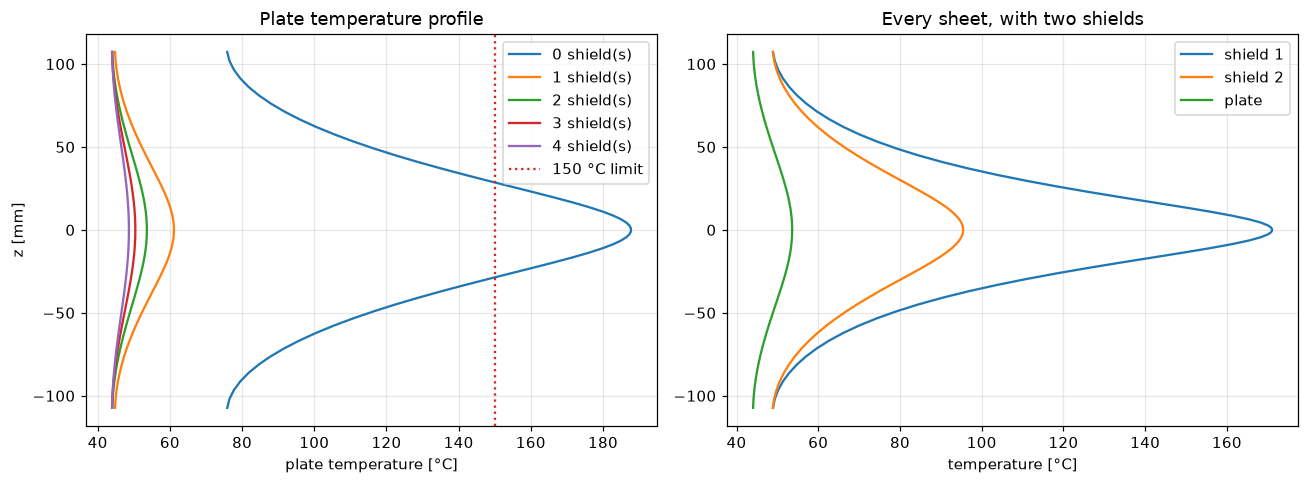

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for res in results:
    axes[0].plot(res.T_sheets[-1] - C, res.z * 1e3, label=f"{res.n_shields} shield(s)")
axes[0].axvline(150, color="tab:red", ls=":", label="150 °C limit")
axes[0].set_xlabel("plate temperature [°C]"); axes[0].set_ylabel("z [mm]")
axes[0].set_title("Plate temperature profile"); axes[0].legend()

res = results[2]
for k, T in enumerate(res.T_sheets):
    name = "plate" if k == len(res.T_sheets) - 1 else f"shield {k + 1}"
    axes[1].plot(T - C, res.z * 1e3, label=name)
axes[1].set_xlabel("temperature [°C]"); axes[1].set_title("Every sheet, with two shields")
axes[1].legend()
plt.tight_layout(); plt.show()

With shields the gaps shrink: one shield leaves two 5 mm gaps. Still air across a few
millimetres conducts about as much heat as ε = 0.2 surfaces radiate, so each extra shield
helps less than the textbook 1/(N + 1) rule for radiation alone would suggest. Even so,
**one shield cuts the plate's peak from about 190 °C to about 60 °C**.

## Part 3 — no plate, shields only

With the plate removed, the outermost shield takes the plate's place, 10 mm from the tube.
Any further shields are evenly spaced inside that gap. Now the outermost shield must stay
below 150 °C.

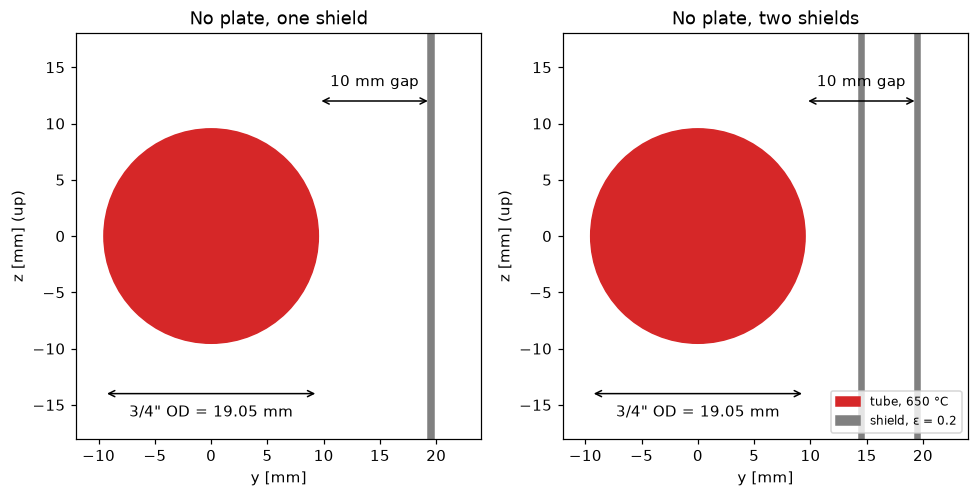

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
section(axes[0], 1, zoom=True, plate=False); axes[0].set_title("No plate, one shield")
section(axes[1], 2, zoom=True, plate=False); axes[1].set_title("No plate, two shields")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

 shields | outer shield peak | outer shield mean | hottest shield
   1     |       131.1 °C    |       72.0 °C    |    131 °C
   2     |        82.8 °C    |       59.3 °C    |    168 °C
   3     |        69.2 °C    |       56.1 °C    |    175 °C
   4     |        63.0 °C    |       54.6 °C    |    177 °C



Shields needed to keep the outermost shield below 150 °C: 1


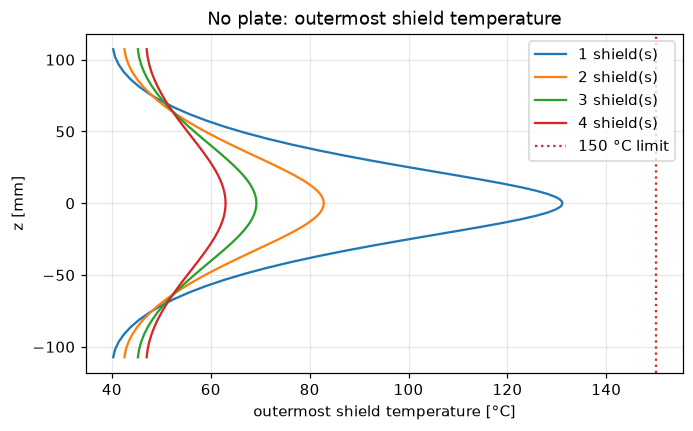

In [11]:
bare = [rad.solve(s, n, plate=False) for n in range(1, 5)]
print(" shields | outer shield peak | outer shield mean | hottest shield")
for res in bare:
    print(f"   {res.n_shields}     |      {res.T_plate_max - C:6.1f} °C    |     {res.T_plate_mean - C:6.1f} °C    | "
          f"{res.T_sheets.max() - C:6.0f} °C")
n_bare = rad.shields_required(s, plate=False)
print(f"\nShields needed to keep the outermost shield below 150 °C: {n_bare}")

fig, ax = plt.subplots(figsize=(7, 4))
for res in bare:
    ax.plot(res.T_sheets[-1] - C, res.z * 1e3, label=f"{res.n_shields} shield(s)")
ax.axvline(150, color="tab:red", ls=":", label="150 °C limit")
ax.set_xlabel("outermost shield temperature [°C]"); ax.set_ylabel("z [mm]")
ax.set_title("No plate: outermost shield temperature"); ax.legend()
plt.show()

A single ε = 0.2 shield runs cooler than the ε = 0.8 plate in the same spot. It absorbs only a
fifth of the radiation that reaches it. It also emits poorly, though, so most of the heat it
does absorb leaves by convection to room air.

In [12]:
cases3 = {
    "base case": {},
    "tube ε = 1.0 (black)": dict(eps_tube=1.0),
    "shield ε = 0.3": dict(eps_shield=0.3),
    "thin shields, 0.1 mm": dict(shield_thickness=0.0001),
    "tube ε = 1, shield ε = 0.3, 0.1 mm": dict(eps_tube=1.0, eps_shield=0.3, shield_thickness=0.0001),
}
print(f"{'case':36s} | peak, 1 shield | peak, 2 shields | shields needed")
for name, change in cases3.items():
    sc = replace(s, **change)
    r1, r2 = rad.solve(sc, 1, n_strips=40, plate=False), rad.solve(sc, 2, n_strips=40, plate=False)
    n = rad.shields_required(sc, plate=False, n_strips=40)
    print(f"{name:36s} | {r1.T_plate_max - C:11.0f} °C | {r2.T_plate_max - C:12.0f} °C | {n}")

case                                 | peak, 1 shield | peak, 2 shields | shields needed


base case                            |         131 °C |           83 °C | 1


tube ε = 1.0 (black)                 |         151 °C |           93 °C | 2


shield ε = 0.3                       |         163 °C |          100 °C | 2


thin shields, 0.1 mm                 |         159 °C |          109 °C | 2


tube ε = 1, shield ε = 0.3, 0.1 mm   |         223 °C |          149 °C | 2


## How sensitive are parts 1 and 2?

In [13]:
cases = {
    "base case": {},
    "tube ε = 1.0 (black)": dict(eps_tube=1.0),
    "tube ε = 0.6": dict(eps_tube=0.6),
    "plate ε = 0.3": dict(eps_plate=0.3),
    "plate ε = 1.0": dict(eps_plate=1.0),
    "stainless plate, k = 16": dict(k_plate=16.0),
    "aluminium plate, k = 200": dict(k_plate=200.0),
    "tube ε = 1, plate ε = 1, k = 16": dict(eps_tube=1.0, eps_plate=1.0, k_plate=16.0),
    "thin shields, 0.1 mm": dict(shield_thickness=0.0001),
}
print(f"{'case':34s} | peak, 0 shields | peak, 1 shield | shields needed")
for name, change in cases.items():
    sc = replace(s, **change)
    r0, r1 = rad.solve(sc, 0, n_strips=40), rad.solve(sc, 1, n_strips=40)
    n = rad.shields_required(sc, n_strips=40)
    print(f"{name:34s} | {r0.T_plate_max - C:12.0f} °C | {r1.T_plate_max - C:11.0f} °C | {n}")

case                               | peak, 0 shields | peak, 1 shield | shields needed


base case                          |          188 °C |          61 °C | 1


tube ε = 1.0 (black)               |          216 °C |          67 °C | 1


tube ε = 0.6                       |          156 °C |          54 °C | 1


plate ε = 0.3                      |          120 °C |          67 °C | 0


plate ε = 1.0                      |          203 °C |          59 °C | 1


stainless plate, k = 16            |          222 °C |          68 °C | 1


aluminium plate, k = 200           |          146 °C |          55 °C | 0


tube ε = 1, plate ε = 1, k = 16    |          272 °C |          73 °C | 1


thin shields, 0.1 mm               |          188 °C |          64 °C | 1


## Conclusions

1. **Plate temperature:** the plate peaks at about **190 °C** along the band opposite the
   tube, and averages about 120 °C. A single-temperature estimate (about 120 °C) hides the
   hot band.
2. **Heat shields:** **one** ε = 0.2 shield, placed midway in the gap, brings the peak down
   to about 60 °C, well under 150 °C. One shield is enough in every case in the sensitivity
   table, and none is needed only if the plate is low-emissivity (ε ≈ 0.3) or aluminium.
3. **No plate:** a single shield in the plate's place peaks at about **131 °C**, so **one**
   shield meets the 150 °C limit in the base case. The margin is thin, though: a black tube,
   shields with ε = 0.3, or 0.1 mm shields each push a lone shield over 150 °C. **Two shields
   (outer one at about 83 °C) are the robust choice**, and they stay at or below 150 °C even
   when all three of those changes are combined.

**Limitations**

- Hot air rising from the tube is ignored, as requested. It would add heat to the upper part
  of the plate, or to the first shield once one is fitted, so the no-shield temperatures here
  are on the low side.
- Shields and the plate are assumed to be the same size and perfectly parallel. Mounting
  brackets that conduct heat between them are not modelled.
- Room-air convection uses one average coefficient for the whole height. Air in the narrow
  gaps is taken as still, with no chimney flow up through them.